# Vision Transformer

Ảnh bàn học có sách ở một góc và đèn ở góc kia. CNN ghép cửa sổ nhỏ qua nhiều lớp để nối hai vùng. Transformer đã biết cho token trong câu trao đổi thông tin bằng attention; liệu các mảnh ảnh có thể trở thành token? Bài này đưa một ảnh nhỏ qua đường ảnh → patch → vector → attention, và hỏi phần nào giúp mạng biết vị trí của từng mảnh.

> **Mục tiêu sau bài này**
>
> - Chia ảnh thành patch, đếm số token, chiều vector và chi phí attention theo độ phân giải.
> - Viết patch embedding bằng phép biến đổi tensor và đối chiếu convolution.
> - Giải thích vai trò position embedding, class token, và nội suy bảng vị trí khi đổi kích thước ảnh.
> - So sánh giả định và chi phí của ViT với CNN để chọn baseline.

## Patch là một đơn vị đọc ảnh

Patch là khối điểm ảnh không chồng lấn. Với ảnh $H\times W$ có $C$ kênh, patch $P\times P$, nếu hai chiều chia hết cho $P$ thì số patch là $L=(H/P)(W/P)$, mỗi patch có $CP^2$ số. Ta trải mỗi patch thành vector rồi nhân cùng một ma trận $E$ để có vector $D$ chiều. $D$ là chiều biểu diễn được chọn, không phải số pixel.



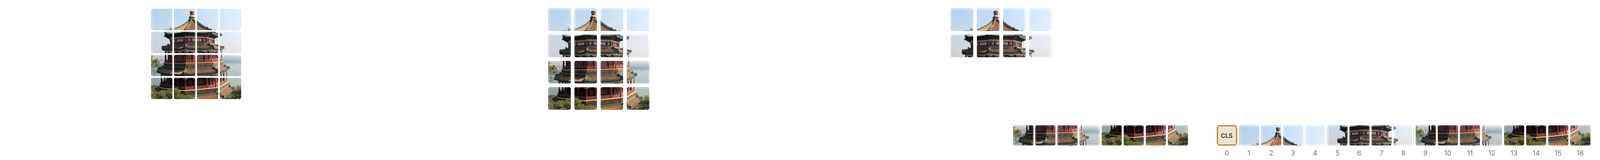

Với ảnh RGB $224\times224$, patch 16 cho $14\cdot14=196$ token ảnh, mỗi patch thô có $3\cdot16^2=768$ số. Bản ViT-Base chọn $D=768$; việc trùng với 768 số thô chỉ là tình cờ của cấu hình, vì ViT-Large cùng patch 16 dùng $D=1024$. Tên ViT-B/16 đọc là bản Base với patch $16\times16$. Cùng phép đếm: ViT-B/32 với ảnh 384 có $12 \cdot 12 = 144$ patch, thêm CLS (mục sau) là 145 token; mô hình đa phương thức cắt ảnh 336 thành patch 14 thì một ảnh chiếm $24^2 = 576$ token; bộ mã hóa VQ thu ảnh 256 đi 16 lần mỗi chiều cho $16^2 = 256$ token, và mô hình tự hồi quy phải sinh lần lượt từng ấy token. MAE che ngẫu nhiên 75% số patch và chỉ cho encoder đọc 25% còn lại, nên mỗi bước pretrain rẻ hơn nhiều; một decoder nhỏ dựng lại phần bị che.

[Bài báo ViT](https://arxiv.org/abs/2010.11929) (Dosovitskiy và cộng sự, 2020) đưa chuỗi patch embedding vào một Transformer encoder gần như giữ nguyên từ NLP; tên bài báo nói đúng ý đó: một ảnh đáng giá $16\times16$ từ. Các mục sau dựng từng bước trên một ảnh $4\times4$, đủ nhỏ để kiểm bằng tay.

**Hỏi nhanh.** Ảnh RGB $32\times 32$ được chia thành các patch $8\times 8$. Có bao nhiêu patch, và mỗi patch thô dài bao nhiêu số?

- A. 64 patch, mỗi patch 192 số
- B. 16 patch, mỗi patch 192 số
- C. 16 patch, mỗi patch 64 số
- D. 4 patch, mỗi patch 768 số

<details><summary>Đáp án</summary>

B. 16 patch, mỗi patch 192 số

Mỗi chiều có 4 patch, nên có $4\cdot 4 = 16$ patch. Mỗi patch chứa $3\cdot 8\cdot 8 = 192$ giá trị.

</details>

## Ví dụ tính tay rồi chia bằng tensor

Ta đánh số ảnh xám từ 0 đến 15 theo hàng. Patch trên trái gồm 0, 1, 4, 5; trên phải gồm 2, 3, 6, 7. Nếu flatten toàn ảnh rồi cứ cắt mỗi bốn số, ta nhận 0, 1, 2, 3 là một patch — đó là một hàng, không phải ô vuông.

`unfold` tạo cửa sổ theo chiều; `permute` đặt thứ tự batch, hàng patch, cột patch, kênh, hàng trong patch, cột trong patch. `reshape` chỉ dùng sau khi thứ tự trục đã đúng.

In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(54)
images = torch.arange(16, dtype=torch.float32).reshape(1, 1, 4, 4)
patch_size = 2
windows = images.unfold(2, patch_size, patch_size)
windows = windows.unfold(3, patch_size, patch_size)
patches = windows.permute(0, 2, 3, 1, 4, 5).reshape(1, 4, 4)
print(patches[0].to(torch.int64).numpy())
print(tuple(patches.shape))

[[ 0  1  4  5]
 [ 2  3  6  7]
 [ 8  9 12 13]
 [10 11 14 15]]
(1, 4, 4)


Đọc dòng đầu để đối chiếu bốn ô tay. Shape `(1,4,4)` có hai chiều cùng bằng 4 nhưng ý nghĩa khác: bốn patch và bốn số trong mỗi patch. Khi tăng số kênh, chiều cuối tăng, số patch giữ nguyên.



**Hỏi nhanh.** Ảnh RGB $4\times 4$, patch cỡ 2, nên `windows` có shape `(1, 3, 2, 2, 2, 2)`. Một bạn bỏ bước `permute` và gọi thẳng `windows.reshape(1, 4, 12)`. Hàng đầu của kết quả chứa gì?

- A. Ba kênh của patch trên trái, nên `permute` là thừa
- B. Ba kênh của bốn điểm ảnh ở hàng ảnh đầu tiên
- C. Kênh R của ba patch đầu tiên
- D. Không có gì, vì không reshape được tensor sáu chiều

<details><summary>Đáp án</summary>

C. Kênh R của ba patch đầu tiên

Các trục của `windows` lần lượt là batch, kênh, hàng patch, cột patch, hàng trong patch, cột trong patch, và `reshape` đọc đúng theo thứ tự đó. Vì vậy mười hai số đầu là kênh R của patch 0, 1 và 2, mỗi patch bốn số. Shape đúng, code không báo lỗi, nhưng mỗi “patch” trộn ba patch thật. Đáp án “hàng ảnh đầu tiên” quên rằng `unfold` đã gom thành ô vuông. Với ảnh xám, trục kênh dài 1 nên bỏ `permute` vẫn ra đúng. Lỗi chỉ lộ ra khi kiểm với ảnh nhiều kênh.

</details>

## Patch embedding là phép tuyến tính dùng chung

Với vector patch $\mathbf{p}_i$, ta tính $\mathbf{z}_i=\mathbf{p}_iE+\mathbf{b}$, trong đó $E$ có shape $(CP^2,D)$. Mọi patch dùng chung $E$. Cách khác là conv có kernel $P$, stride $P$, không padding; mỗi kênh đầu ra là một chiều embedding. Hai cách tương đương nếu xếp trọng số cùng thứ tự.

Ta đặt trọng số cụ thể để kết quả dễ kiểm, rồi đối chiếu:

In [ ]:
projection = nn.Linear(4, 3)
with torch.no_grad():
    projection.weight.copy_(torch.tensor([[1., 0., 0., 0.],
                                          [0., 1., 0., 0.],
                                          [0.25, 0.25, 0.25, 0.25]]))
    projection.bias.zero_()
tokens = projection(patches)

patch_conv = nn.Conv2d(1, 3, kernel_size=2, stride=2)
with torch.no_grad():
    patch_conv.weight.copy_(projection.weight.reshape(3, 1, 2, 2))
    patch_conv.bias.copy_(projection.bias)
    conv_tokens = patch_conv(images).flatten(2).transpose(1, 2)
print(tokens[0].detach().tolist())
print(torch.allclose(tokens, conv_tokens))

[[0.0, 1.0, 2.5], [2.0, 3.0, 4.5], [8.0, 9.0, 10.5], [10.0, 11.0, 12.5]]
True


Token đầu là $(0,1,2.5)$: hai chiều đầu đọc hai ô đầu, chiều thứ ba lấy trung bình $(0+1+4+5)/4$. `True` xác nhận hai cách xếp ô nhất quán. Trọng số ở đây đặt tay để dễ đọc; trong ViT thật, $E$ được học cùng phần còn lại của mạng.

**Hỏi nhanh.** Tăng $D$ từ 3 lên 12, giữ nguyên ảnh và patch size. Đại lượng nào không đổi?

- A. Số patch
- B. Số tham số của phép chiếu
- C. Chiều của mỗi vector token
- D. Shape trọng số của Conv2d tương đương

<details><summary>Đáp án</summary>

A. Số patch

Số patch chỉ phụ thuộc kích thước ảnh và kích thước patch, nên vẫn là 4. $E$ đổi từ $(4, 3)$ sang $(4, 12)$, nên số tham số, chiều token và số kênh ra của Conv2d đều tăng theo $D$.

</details>

**Hỏi nhanh.** Patch embedding của ViT-B/16 là `nn.Conv2d(3, 768, kernel_size=16, stride=16)`, chạy trên ảnh $224\times 224$. Lớp này có bao nhiêu tham số?

- A. $150\,528$
- B. $115\,756\,032$
- C. $589\,824$
- D. $590\,592$

<details><summary>Đáp án</summary>

D. $590\,592$

Trọng số có $768\cdot 3\cdot 16\cdot 16 = 589\,824$ số, cộng 768 bias thành $590\,592$. Con số $589\,824$ là quên bias. Số tham số không phụ thuộc 196 patch, vì mọi patch dùng chung bộ lọc. Nếu mỗi vị trí có bộ lọc riêng thì mới thành $196\cdot 590\,592 = 115\,756\,032$. Còn $150\,528 = 196\cdot 768$ là số giá trị output của một ảnh, không phải số tham số.

</details>

## Attention nối các mảnh bằng nội dung

Trong attention, từ token ta tạo query $Q$, key $K$ và value $V$. Điểm $QK^\top/\sqrt{d_k}$ đo mức phù hợp, softmax theo từng hàng tạo trọng số cộng thành 1, rồi lấy tổng có trọng số của $V$:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V.$$

$d_k$ là số chiều query/key mỗi head, không phải số patch. Ô $(i,j)$ trong ma trận attention nói token $i$ đọc token $j$ bao nhiêu ở head này. Nó không tự là xác suất vật thể nằm ở patch $j$, cũng không chứng minh vùng ấy gây ra quyết định.

Điểm khác CNN nằm ở chỗ ngay từ lớp đầu, mọi patch đã có đường đọc trực tiếp mọi patch khác: quyển sách và cái đèn ở hai góc bàn trao đổi trong một bước. CNN phải xếp chồng nhiều lớp thì receptive field mới phủ được hai góc (bài 5.1).

Mỗi block của ViT ghép attention và MLP; trước mỗi phần có LayerNorm, sau mỗi phần có residual connection. Class token (CLS) là một vector học được, ghép vào đầu chuỗi nên chuỗi dài $L+1$. Nó không ứng với vùng ảnh nào, chỉ đọc các patch qua attention, và output của nó ở lớp cuối đi vào head phân loại. Với ViT-B/16 trên ảnh 224, chuỗi vào encoder có shape $(B,197,768)$; mỗi lớp có 12 head, mỗi head một ma trận $197\times197$. Cách khác là bỏ CLS và lấy trung bình output các patch (mean pooling); phụ lục bài báo ViT cho thấy hai cách tốt ngang nhau khi learning rate được chỉnh riêng cho từng cách.



**Hỏi nhanh.** Lưới có $14\times 14$ patch. Sau **một** lớp attention, token của patch $(0, 0)$ đã nhận được thông tin trực tiếp từ patch $(13, 13)$ chưa? Nếu thay bằng CNN chỉ gồm conv $3\times 3$ stride 1, không pooling, thì cần ít nhất bao nhiêu lớp để receptive field của ô $(0, 0)$ chứa ô $(13, 13)$?

- A. Rồi, và cần 7 lớp conv
- B. Rồi, và cần 13 lớp conv
- C. Chưa, cần nhiều lớp attention, và cần 7 lớp conv
- D. Chưa, cần nhiều lớp attention, và cần 13 lớp conv

<details><summary>Đáp án</summary>

B. Rồi, và cần 13 lớp conv

Attention tính điểm cho mọi cặp token. Ngay ở lớp đầu, hàng của $(0, 0)$ đã có trọng số cho $(13, 13)$. Trọng số ấy có thể nhỏ, nhưng đường đi đã có. Sau $n$ lớp conv $3\times 3$ stride 1, receptive field là $(2n + 1)\times(2n + 1)$ quanh ô đang xét, tức với xa được $n$ ô mỗi phía. Ô $(13, 13)$ cách 13 ô, nên cần 13 lớp. Bảy lớp cho cửa sổ $15\times 15$, rộng hơn cả lưới, nhưng tâm nằm ở góc nên chỉ với tới $(7, 7)$.

</details>



## Vì sao cần thông tin vị trí?

Attention dựa vào nội dung không biết token này từ góc trái hay góc phải. Nếu đảo thứ tự token và đảo đầu ra tương ứng, self-attention thông thường không có position vẫn cho cùng quan hệ nội dung. Mean pooling trên đầu ra vì vậy không phân biệt cùng tập mảnh bị đổi chỗ.



Position embedding thêm thông tin vị trí vào token trước encoder. Nếu đổi ảnh nhưng giữ các mã tại vị trí của chúng, model có cơ sở phân biệt bố cục. Đổi cả token và mã đi cùng nó chỉ là đổi cách sắp danh sách, chưa thay quan hệ vị trí được biểu diễn.

ViT gốc dùng bảng vị trí 1D học được: patch đánh số theo hàng từ 0 đến $L-1$, mỗi chỉ số và CLS có một vector riêng, cả bảng có shape $(1,L+1,D)$ và được cộng vào token. Bảng không ghi sẵn rằng trên lưới $14\times14$, patch 0 và patch 14 kề nhau theo chiều dọc; model tự học điều đó từ dữ liệu. Bài báo cho thấy sau huấn luyện, vector vị trí của các patch cùng hàng hoặc cùng cột giống nhau hơn, và các mã vị trí 2D thiết kế sẵn không cho lợi ích đáng kể.

Ta kiểm tính đối xứng bằng một block nhỏ khởi tạo ngẫu nhiên, vì câu hỏi ở đây là về cấu trúc chứ chưa phải về điều model học được. Dropout tắt để khác biệt không do ngẫu nhiên.

In [ ]:
encoder = nn.TransformerEncoderLayer(
    d_model=3, nhead=1, dim_feedforward=6,
    dropout=0.0, batch_first=True,
)
encoder.eval()
permutation = torch.tensor([2, 0, 3, 1])
positions = torch.tensor([[[0.4, 0.0, 0.0],
                           [0.0, 0.4, 0.0],
                           [0.0, 0.0, 0.4],
                           [0.2, -0.3, 0.1]]])
with torch.no_grad():
    pooled = encoder(tokens).mean(dim=1)
    shuffled = encoder(tokens[:, permutation]).mean(dim=1)
    with_position = encoder(tokens + positions).mean(dim=1)
    shuffled_content = encoder(tokens[:, permutation] + positions).mean(dim=1)
print("without position:", torch.allclose(pooled, shuffled, atol=1e-5))
print("with fixed positions:", torch.allclose(with_position, shuffled_content, atol=1e-5))

without position: True
with fixed positions: False


Dòng `True` xác nhận đối xứng khi chưa có vị trí: đảo các mảnh thì kết quả sau pooling không đổi, nên sách ở góc trái hay góc phải là như nhau với block này. Dòng `False` cho thấy cộng mã vị trí cố định đã phá đối xứng đó: cùng tập mảnh ở bố cục khác cho output khác. Dùng thông tin vị trí ấy thế nào để nhận ra bàn học là phần model học từ dữ liệu, loss và validation.

**Hỏi nhanh.** Ta đảo thứ tự các token ảnh, và position embedding cũng đi theo từng token. Sau đó lấy mean pooling. Vì sao kết quả có thể giữ nguyên?

- A. Vì position embedding chưa được train nên chưa có tác dụng
- B. Vì mean pooling xóa hết thông tin vị trí trong token
- C. Vì chỉ thứ tự danh sách thay đổi, mỗi patch vẫn giữ mã vị trí cũ
- D. Vì encoder ở chế độ `eval()` nên bỏ qua position embedding

<details><summary>Đáp án</summary>

C. Vì chỉ thứ tự danh sách thay đổi, mỗi patch vẫn giữ mã vị trí cũ

Mỗi patch vẫn đi cùng mã vị trí của chính nó, nên tập các cặp nội dung và vị trí không đổi. Self-attention và mean pooling không phụ thuộc thứ tự liệt kê. Mã vị trí ngẫu nhiên vẫn phá được đối xứng, như dòng `False` cho thấy. Mean pooling lấy trung bình những output đã chịu ảnh hưởng của vị trí, còn `eval()` chỉ tắt dropout. Muốn đổi bố cục thì phải đổi nội dung tại các vị trí, và giữ mã vị trí tại chỗ.

</details>

## CNN và ViT: so giả định trước khi so điểm

CNN có thiên hướng cục bộ và chia sẻ trọng số theo vị trí. ViT với attention toàn cục có đường trao đổi trực tiếp giữa patch xa, nhưng mất thông tin bên trong patch nếu projection nén quá mạnh, và phải học quan hệ không gian qua biểu diễn vị trí. “Toàn cục” không đồng nghĩa tự hiểu mọi quan hệ.

Ít giả định có sẵn thì phải học nhiều hơn từ dữ liệu. Bài báo ViT báo cáo rằng khi chỉ huấn luyện trên ImageNet (khoảng 1.3 triệu ảnh) mà không dùng regularization mạnh, ViT kém ResNet cùng cỡ vài điểm phần trăm; khi pretrain trên JFT-300M (303 triệu ảnh), ViT vượt ResNet và tốn ít tài nguyên pretrain hơn, rồi fine-tune tốt sang các tập nhỏ.

**Hỏi nhanh.** Train từ đầu trên 3000 ảnh. Một CNN nhỏ đạt 85% trên validation. Một ViT nhỏ có số tham số tương đương đạt 100% trên train nhưng chỉ 70% trên validation. Lý do khả dĩ nhất là gì?

- A. ViT thiếu giả định cục bộ nên overfit khi có ít ảnh
- B. ViT underfit, cần thêm lớp để tăng sức chứa
- C. Code ViT có lỗi, vì attention toàn cục phải tốt hơn
- D. Validation của ViT bị rò dữ liệu từ tập train

<details><summary>Đáp án</summary>

A. ViT thiếu giả định cục bộ nên overfit khi có ít ảnh

Train 100% mà validation 70% là overfit, không phải underfit. CNN có sẵn giả định cục bộ và chia sẻ trọng số. ViT phải tự học quan hệ không gian từ dữ liệu, nên với ít ảnh nó dễ học thuộc. Rò dữ liệu thường làm validation cao lên chứ không thấp đi. Nhìn toàn cục cũng không bảo đảm tốt hơn, đúng như bài báo ViT cho thấy trên dữ liệu cỡ vừa. Hướng xử lý là dùng checkpoint pretrained, augmentation mạnh, hoặc giữ CNN.

</details>

Với attention đầy đủ, ma trận điểm có $L^2$ ô cho mỗi head, hoặc $(L+1)^2$ khi có CLS. Giữ patch size, tăng gấp đôi cả hai chiều ảnh làm số patch gấp 4 và số ô attention gấp 16. Convolution có kernel cố định thường tăng công việc theo diện tích, khoảng gấp 4 trong so sánh tương ứng. Phần MLP và các phép chiếu của ViT chỉ tăng theo $L$, tức gấp 4, nên tổng thời gian tăng ít hơn 16 lần; runtime thật còn phụ thuộc implementation và bộ nhớ activation, vì vậy ước lượng trước rồi đo.



ViT pretrained có thể là baseline mạnh khi asset và preprocessing phù hợp. Train ViT lớn từ đầu trên 60 ảnh bàn học khó kiểm soát hơn một baseline nhỏ. Patch quá lớn có thể làm chữ rất nhỏ bị gộp; patch quá nhỏ tăng chi phí. Chọn theo đối tượng, dữ liệu và ngân sách, rồi so trên cùng split.

## Bẫy cài đặt

> **Số token và checkpoint phải tương thích**
>
> Đổi độ phân giải ảnh làm đổi số patch, nên bảng vị trí học ở lưới cũ không còn khớp. Không cắt bớt hay lặp vector vị trí chỉ để code hết lỗi shape: bảng phải được nội suy theo lưới 2D.

Bài báo ViT fine-tune ở độ phân giải cao hơn lúc pretrain, giữ nguyên patch size, và nội suy 2D bảng vị trí theo vị trí của patch trong ảnh gốc. Các bước là: tách vector CLS, đưa $L$ vector còn lại về lưới $h\times w\times D$, nội suy lưới sang kích thước mới, trải lại rồi ghép CLS vào đầu. Để thấy hình học được giữ, ta dùng một bảng vị trí tự đặt, trong đó vector của mỗi patch chính là (hàng, cột) của nó, còn CLS là $(-1,-1)$:

In [ ]:
import torch.nn.functional as F

def resize_position_table(table, old_grid, new_grid):
    cls_part, grid_part = table[:, :1], table[:, 1:]
    dim = table.shape[-1]
    grid = grid_part.reshape(1, old_grid, old_grid, dim).permute(0, 3, 1, 2)
    grid = F.interpolate(grid, size=(new_grid, new_grid),
                         mode="bilinear", align_corners=True)
    grid_part = grid.permute(0, 2, 3, 1).reshape(1, new_grid * new_grid, dim)
    return torch.cat([cls_part, grid_part], dim=1)

rows, cols = torch.meshgrid(torch.arange(4.0), torch.arange(4.0), indexing="ij")
coords = torch.stack([rows, cols], dim=-1).reshape(1, 16, 2)
table = torch.cat([torch.full((1, 1, 2), -1.0), coords], dim=1)
resized = resize_position_table(table, old_grid=4, new_grid=7)
print(tuple(table.shape), "->", tuple(resized.shape))
print("CLS:", resized[0, 0].tolist())
print("row of first column:", resized[0, 1:, 0].reshape(7, 7)[:, 0].tolist())

(1, 17, 2) -> (1, 50, 2)
CLS: [-1.0, -1.0]
row of first column: [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]


Bảng đi từ 17 lên 50 vector, tức CLS cộng lưới $7\times7$. CLS giữ nguyên $(-1,-1)$, còn tọa độ hàng ở cột đầu chạy đều từ 0 đến 3: mỗi vị trí mới nhận vector của đúng chỗ tương ứng trên lưới cũ. Ví dụ dùng bilinear để số dễ đọc; thư viện thường dùng bicubic. Sau khi nội suy vẫn cần fine-tune ở độ phân giải mới, vì bảng chỉ là điểm xuất phát hợp lý.



**Hỏi nhanh.** Checkpoint ViT-B/16 train ở $224\times 224$ có bảng vị trí shape `(1, 197, 768)`. Bây giờ fine-tune ở $384\times 384$, vẫn giữ patch 16. Bảng mới cần bao nhiêu vector?

- A. 197
- B. 337
- C. 576
- D. 577

<details><summary>Đáp án</summary>

D. 577

Lưới mới có $(384/16)^2 = 24^2 = 576$ patch, cộng CLS thành 577. 576 là quên CLS. 337 đến từ $197\cdot 384/224$, tức phóng theo cạnh ảnh thay vì theo số ô của lưới. Giữ 197 chỉ đúng khi resize ảnh về 224, mà như vậy thì mất lợi ích của độ phân giải cao.

</details>

Ảnh không chia hết cho patch cần resize, crop hoặc padding có chủ đích. Padding làm thêm nội dung giả; một số cấu trúc cần mask. Tên model không cho biết preprocessing chính xác. Attention map sáng ở vùng nào chỉ cho một dạng quan hệ nội bộ; bài 5.9 dùng can thiệp để đọc hành vi cẩn thận hơn.

## Khi đi thi

- **Đếm token trước khi đổi cấu hình.** $L=(H/P)(W/P)$, cộng 1 nếu có CLS; phần attention mỗi head, mỗi lớp là $L^2$ ô. Tăng gấp đôi cạnh ảnh nhân phần này lên 16 lần, nên ước lượng bộ nhớ và thời gian trước khi chạy.
- **Đọc cấu hình checkpoint.** Patch size, độ phân giải lúc train, mean/std của processor, CLS hay mean pooling, mapping lớp. Đổi độ phân giải thì nội suy 2D bảng vị trí rồi fine-tune.
- **In shape lưới token.** Ảnh không chia hết cho patch phải resize, crop hoặc pad có chủ đích; dữ liệu để kênh ở trục cuối phải `permute` trước Conv2d.
- **Giữ pixel cho chi tiết nhỏ.** Resize mạnh trước model làm mất thông tin mà không model nào bù được; cắt ô ở độ phân giải gốc hoặc tăng độ phân giải, rồi tính lại chi phí.
- **So trên cùng validation, đo cả thời gian.** Nhân thời gian mỗi ảnh với số ảnh test và so với giới hạn của đề; chênh điểm nhỏ không bù được một lần quá giờ.
- **Ít dữ liệu, không pretrained: thử CNN trước.** CNN nhỏ với augmentation thường là baseline an toàn hơn ViT train từ đầu. Đọc kỹ luật về model được phép trước khi gọi bất kỳ thư viện model nào.

## Tóm tắt

ViT biến patch thành token bằng projection chung, thêm thông tin vị trí rồi trao đổi bằng Transformer. Thiếu vị trí, model không phân biệt được các bố cục của cùng một tập patch; đổi độ phân giải thì bảng vị trí phải nội suy 2D. Class token là một cách tổng hợp, mean pooling là cách khác. Lợi thế nối xa đi kèm chi phí attention bậc hai theo số token và nhu cầu dữ liệu lớn; lựa chọn kiến trúc dựa trên nhiệm vụ, dữ liệu và ngân sách.

## Kiểm tra cuối bài

**Câu 1.** Một đề vật lý cho mỗi mẫu một tensor shape `(64, 64, 2)`, là hai thành phần của một trường vector đo trên lưới $64\times 64$. Một đội dùng ViT patch $8\times 8$ có class token. Chuỗi vào encoder dài bao nhiêu, và mỗi patch thô dài bao nhiêu số?

- A. 64 token, mỗi patch 128 số
- B. 65 token, mỗi patch 128 số
- C. 64 token, mỗi patch 192 số
- D. 65 token, mỗi patch 192 số

<details><summary>Đáp án</summary>

B. 65 token, mỗi patch 128 số

Lưới có $(64/8)^2 = 64$ patch, thêm class token thành 65. Dữ liệu có hai kênh, nên mỗi patch có $2\cdot 8\cdot 8 = 128$ số. 192 là thói quen nhân với ba kênh RGB. Dữ liệu để kênh ở trục cuối, nên trước Conv2d còn phải `permute` về `(2, 64, 64)`.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=11)

</details>

**Câu 2.** ViT đọc ảnh như một chuỗi patch. Một đội muốn giữ mọi chi tiết, nên cho mỗi pixel của ảnh $224\times 224$ thành một token. So với patch $16\times 16$, tức 196 token, ma trận attention của mỗi head ở mỗi lớp có số ô tăng bao nhiêu lần?

- A. 16
- B. Không đổi, vì ma trận attention có kích thước $D\times D$
- C. 256
- D. $65\,536$

<details><summary>Đáp án</summary>

D. $65\,536$

Số token tăng từ 196 lên $224^2 = 50\,176$, tức $256 = 16^2$ lần. Ma trận token nhân token tăng $256^2 = 65\,536$ lần, thành khoảng $2.5\cdot 10^9$ ô, cỡ 10 GB float32 cho một head, một lớp, một ảnh. 16 chỉ là tỉ lệ cạnh patch. 256 là tỉ lệ số token, quên rằng ma trận có hai chiều token. Ma trận attention có kích thước $L\times L$, không phải $D\times D$. Gom pixel thành patch chính là cách ViT rút chuỗi xuống độ dài chịu được.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 260](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=93)

</details>

**Câu 3.** Ảnh $230\times 230$ được đưa thẳng vào `nn.Conv2d(3, 768, kernel_size=16, stride=16)`, không padding. Kết quả ra sao?

- A. Báo lỗi, vì 230 không chia hết cho 16
- B. Tự đệm thêm để ra lưới $15\times 15$, tức 225 token
- C. Ra lưới $14\times 14$, còn 6 hàng và 6 cột pixel cuối không được đọc
- D. Ra lưới $14\times 14$, phần dư được gộp vào hàng và cột patch cuối

<details><summary>Đáp án</summary>

C. Ra lưới $14\times 14$, còn 6 hàng và 6 cột pixel cuối không được đọc

Mỗi chiều có $\lfloor(230 - 16)/16\rfloor + 1 = 14$ vị trí, phủ $14\cdot 16 = 224$ pixel. 6 hàng dưới và 6 cột phải không nằm trong cửa sổ nào. Conv2d không báo lỗi và không tự padding. Kernel cố định $16\times 16$, nên cũng không gộp được phần dư. Lỗi im lặng này làm mất viền ảnh, nên cần resize, crop hoặc pad có chủ đích, và in shape của lưới token ra để kiểm.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.2(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=6)

</details>

**Câu 4.** Encoder ViT-B/16 chạy trên ảnh 224 trả về `out` shape `(1, 197, 768)`, trong đó token 0 là CLS. Head segmentation cần feature map shape `(1, 768, 14, 14)`. Dòng nào đúng?

- A. `out.reshape(1, 768, 14, 14)`
- B. `out[:, 1:].reshape(1, 768, 14, 14)`
- C. `out[:, 1:].transpose(1, 2).reshape(1, 768, 14, 14)`
- D. `out[:, :196].transpose(1, 2).reshape(1, 768, 14, 14)`

<details><summary>Đáp án</summary>

C. `out[:, 1:].transpose(1, 2).reshape(1, 768, 14, 14)`

Phải bỏ CLS, đưa trục $D$ lên vị trí kênh, rồi mới tách 196 token thành lưới $14\times 14$ theo hàng. `out.reshape(...)` báo lỗi, vì $197\cdot 768$ số không xếp được thành $768\cdot 14\cdot 14$. `out[:, 1:].reshape(...)` chạy được, nhưng đọc dữ liệu theo token trước, nên mỗi “kênh” là một đoạn 196 số cắt ngang nhiều token. Shape đúng mà nội dung bị trộn. `out[:, :196]` giữ CLS và bỏ patch cuối, nên mọi vị trí lệch một ô.

</details>

**Câu 5.** Một ViT patch 16 trên ảnh $224\times 224$ bị quên cộng position embedding. Head đọc output của CLS, model chạy ở `eval()`. Ta thử hai phép tráo. Phép (i) cắt tại pixel 112 theo cả hai chiều, rồi đổi chỗ khối trên trái với khối dưới phải. Phép (ii) đổi chỗ dải dọc cột 0–99 với dải cột 100–199. Logits sau mỗi phép so với ảnh gốc thế nào?

- A. (i) giống ảnh gốc, (ii) có thể khác
- B. (i) có thể khác, (ii) giống ảnh gốc
- C. Cả hai đều giống ảnh gốc
- D. Cả hai đều có thể khác

<details><summary>Đáp án</summary>

A. (i) giống ảnh gốc, (ii) có thể khác

$112 = 7\cdot 16$, nên đường cắt trùng ranh giới patch, và phép (i) chỉ hoán vị các patch nguyên vẹn. Không có vị trí thì attention và MLP xử lý các token như một tập hợp, và CLS đọc tập ấy, nên logits giống ảnh gốc, chỉ khác ở mức làm tròn số thực. 100 và 200 không chia hết cho 16. Các patch vắt qua đường cắt nhận một tổ hợp pixel mới, nên tập token đổi và logits có thể khác. Model như vậy không phân biệt được ảnh với bản xếp lại theo lưới patch. Đây là một phép thử nhanh để phát hiện quên position embedding.

</details>

**Câu 6.** Checkpoint có bảng vị trí `(1, 197, 768)`, gồm CLS rồi lưới $14\times 14$ đánh số theo hàng. Để chạy ảnh 384, một bạn nội suy tuyến tính 1D cả chuỗi 197 vector thành 577 vector. Cách này sai ở đâu?

- A. Không sai, vì nội suy 1D vẫn giữ thứ tự các token
- B. CLS bị trộn vào lưới, và cuối hàng trộn với đầu hàng sau
- C. Không sai nếu fine-tune, vì model sẽ học lại mọi vị trí
- D. Chỉ sai ở viền ảnh, phần giữa giống nội suy 2D

<details><summary>Đáp án</summary>

B. CLS bị trộn vào lưới, và cuối hàng trộn với đầu hàng sau

Trong chuỗi 1D, ngay sau patch 13 ở mép phải hàng 0 là patch 14 ở mép trái hàng 1. Nội suy vì vậy tạo ra vector pha trộn hai mép đối diện, và vector CLS cũng bị kéo vào các vị trí đầu. Khi trải 576 vector thành lưới $24\times 24$, hàng mới không ứng với hàng cũ, nên sai cả ở giữa chứ không riêng viền. Fine-tune có thể sửa dần, nhưng bỏ phí cấu trúc vị trí đã pretrain. Cách đúng là tách CLS ra rồi nội suy 2D trên lưới, như hàm `resize_position_table`.

</details>

**Câu 7.** Ảnh RGB $224\times 224$. Để giữ nét nhỏ, ta đổi patch từ 16 xuống 8 và giữ nguyên mọi thứ khác. Điều nào đúng?

- A. 392 token, ô attention gấp 4, patch thô 384 số
- B. 784 token, ô attention gấp 16, patch thô 192 số
- C. 784 token, ô attention gấp 4, patch thô 192 số
- D. 392 token, ô attention gấp 16, patch thô 384 số

<details><summary>Đáp án</summary>

B. 784 token, ô attention gấp 16, patch thô 192 số

$(224/8)^2 = 784 = 4\cdot 196$ token. Ma trận attention tăng $4^2 = 16$ lần. Mỗi patch còn $3\cdot 8\cdot 8 = 192$ số. Patch size đóng vai stride của patch embedding: stride nhỏ thì có nhiều vị trí hơn, giữ chi tiết mịn hơn nhưng tốn tính toán hơn. 392 là chia đôi theo một chiều thay vì cả hai. Gấp 4 là quên rằng attention tăng theo bình phương số token.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.1(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=4)

</details>

**Câu 8.** Ảnh gốc $2048\times 2048$ có vết nứt rộng khoảng 3 pixel. Pipeline resize ảnh về $224\times 224$ rồi đưa vào ViT-B/16 pretrained, và recall với vết nứt thấp. Thay đổi nào nhắm đúng nguyên nhân?

- A. Tăng $D$ để mỗi token chứa nhiều thông tin hơn
- B. Đổi sang patch 32 để mỗi token nhìn vùng rộng hơn
- C. Thêm head attention để model chú ý vết nứt hơn
- D. Cắt ảnh gốc thành ô nhỏ, đưa từng ô vào model

<details><summary>Đáp án</summary>

D. Cắt ảnh gốc thành ô nhỏ, đưa từng ô vào model

Resize thu mỗi cạnh khoảng $2048/224 \approx 9.1$ lần, nên vết nứt 3 pixel chỉ còn khoảng 0.3 pixel. Thông tin đã mất trước khi vào model, nên tăng $D$ hay thêm head không lấy lại được, còn patch 32 thì gộp còn thô hơn. Cắt thành $8\times 8$ ô $256\times 256$ giữ vết nứt gần như nguyên độ rộng. Đổi lại, số lần chạy model tăng 64 lần, nên cần ước lượng thời gian trước khi chọn.

</details>

**Câu 9.** Trên cùng validation, CNN pretrained đạt macro-F1 0.91 và chạy 40 ms mỗi ảnh. ViT pretrained đạt 0.92 và chạy 160 ms mỗi ảnh, cùng CPU và đã chọn batch tốt nhất. Tập test có $20\,000$ ảnh, giới hạn chạy dự đoán là 30 phút, quá giờ thì 0 điểm. Nên chọn model nào?

- A. CNN, vì ViT cần khoảng 53 phút cho tập test
- B. ViT, vì F1 trên cùng validation cao hơn
- C. Ensemble cả hai, để F1 cao hơn từng model
- D. ViT, chạy một nửa test rồi nộp phần đã xong

<details><summary>Đáp án</summary>

A. CNN, vì ViT cần khoảng 53 phút cho tập test

ViT cần $20\,000\cdot 0.16 = 3200$ giây, khoảng 53 phút, vượt giới hạn. CNN cần 800 giây, khoảng 13 phút. Ensemble phải chạy cả hai, mất khoảng 67 phút. Nộp thiếu nửa test thì nửa còn lại bị chấm sai. Chênh 0.01 F1 trên validation thường vẫn nằm trong nhiễu. Muốn dùng ViT thì phải giảm chi phí trước, như dùng ảnh nhỏ hơn hay model nhỏ hơn, rồi đo lại.

</details>

**Câu 10.** Một đội giữ tỉ lệ khung hình của ảnh. Ảnh A $224\times 224$ cho 196 patch, ảnh B $224\times 320$ cho 280 patch. Để chạy chung một batch qua encoder, đội nối thêm 84 vector 0 vào cuối chuỗi token của A. Còn thiếu gì?

- A. Không thiếu gì, vì vector 0 cho điểm attention bằng 0
- B. Cắt chuỗi của B về 196 token để hai chuỗi bằng nhau
- C. Key padding mask, để token thật không đọc token đệm
- D. Đặt các token đệm lên đầu chuỗi, ngay trước CLS

<details><summary>Đáp án</summary>

C. Key padding mask, để token thật không đọc token đệm

Token đệm không hề trung tính. Sau LayerNorm và các phép chiếu, key và value của nó khác 0. Kể cả khi điểm bằng 0 thì $e^0 = 1$ vẫn chia trọng số cho nó. Vì vậy output của A phụ thuộc vào việc A được ghép batch với ảnh nào. Key padding mask loại các key đệm khỏi softmax, giống cách xử lý câu dài ngắn khác nhau ở bài 3.9. Cắt B về 196 token là bỏ 84 patch bên phải ảnh. Đặt token đệm ở đầu hay ở cuối thì chúng vẫn bị đọc. Mỗi ảnh còn cần bảng vị trí theo đúng lưới của nó: $14\times 14$ cho A, $14\times 20$ cho B.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q2.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=10)

</details>

## Đọc thêm

- Dosovitskiy và cộng sự — [An Image is Worth 16×16 Words](https://arxiv.org/abs/2010.11929): xem kiến trúc patch, class token và điều kiện pretraining của nghiên cứu.
- [PyTorch — TransformerEncoderLayer](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html): đối chiếu `batch_first`, `nhead` và dropout.
- [Dive into Deep Learning — Transformers for Vision](https://d2l.ai/chapter_attention-mechanisms-and-transformers/vision-transformer.html): đọc đường từ ảnh đến encoder sau khi đã kiểm patch bằng tay.

Nguồn ảnh: ảnh tháp là ảnh mẫu `china.jpg` kèm scikit-learn (danielbuechele, Flickr, CC BY 2.0).